
# **Interpolacija**

Neka su dati čvorovi $x_0, x_1, \ldots, x_n$ i odgovarajuće vrednosti funkcije $f_0, f_1, \ldots, f_n$. **Problem interpolacije** je pronaći polinom $P_n(x)$ stepena $n$ takav da važi:
$$P_n(x_i) = f_i, \quad i = 0, 1, \ldots, n.$$

Takav polinom uvek postoji i jedinstven je, ali postoji više oblika u kojima se može zapisati. Mi ćemo obraditi sledeće:

1. **Lagranžov oblik** — teorijski najelegantniji, dobar za izračunavanje u tački
2. **Njutnov oblik sa podeljenim razlikama** — efikasan kada se čvorovi dodaju postepeno
3. **Njutnov oblik sa konačnim razlikama** — prilagođen ekvidistantnim čvorovima


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math

---
## 1. Lagranžov interpolacioni polinom


**Lagranžovi bazisni polinomi** definišu se kao:
$$l_i(x) = \prod_{\substack{j=0 \\ j \neq i}}^{n} \frac{x - x_j}{x_i - x_j}, \quad i = 0, 1, \ldots, n,$$
i zadovoljavaju uslov $l_i(x_j) = \delta_{ij}$.

**Lagranžov interpolacioni polinom** je tada:
$$P_n(x) = \sum_{i=0}^{n} f_i \, l_i(x).$$



### Zadatak 1
Isprogramirati metodu `Lagranz_u_tacki(X, F, x)` koja izračunava vrednost Lagranžovog interpolacionog polinoma funkcije $f$ u tački `x`, na osnovu čvorova `X` i vrednosti funkcije $f$ u tim čvorovima `F`.


In [3]:
def Lagranz_u_tacki(X, F, x):
    """
    Izračunava vrednost Lagranžovog interpolacionog polinoma u tački x.

    Ulaz:
        X : niz čvorova interpolacije
        F : niz vrednosti funkcije u čvorovima (F[i] = f(X[i]))
        x : tačka u kojoj se izračunava vrednost polinoma

    Izlaz:
        Vrednost interpolacionog polinoma P_n(x).
    """
    S = 0
    n = len(X)
    for i in range(n):
        P = 1
        for j in range(n):
            if j != i:
                P = P * (x - X[j]) / (X[i] - X[j])
        S = S + P * F[i]
    return S

### Test primer

Koristimo 4 čvora $X = [-2,\; -0.5,\; 0,\; 1.8]$ i vrednosti $F = \sin(X)$, kako bismo interpolacionim polinomom aproksimirali vrednost $\sin(x)$.

Uporedjujemo dobijenu vrednost sa tačnom vrednošću za različite tačke.


In [4]:
x = np.pi / 2
X = np.array([-2, -0.5, 0, 1.8])
F = np.sin(X)

y_interp = Lagranz_u_tacki(X, F, x)
y_tacno  = np.sin(x)

print("Interpolirana vrednost:", y_interp)
print("Tačna vrednost:", y_tacno)
print("Greška:", abs(y_interp - y_tacno))

Interpolirana vrednost: 1.0168379247797128
Tačna vrednost: 1.0
Greška: 0.0168379247797128



### Zadatak 2
Lagranžov polinom možemo zapisati u standardnoj formi:
$$P_n(x) = a_n x^n + a_{n-1} x^{n-1} + \cdots + a_1 x + a_0.$$
Isprogramirati metodu koja računa koeficijente $[a_n, \ldots, a_0]$ pomoću konvolucije polinoma (funkcija `np.convolve` množi polinome) korišćenjem Lagranžovog oblika interpolacionog polinoma.

Potom, koristeći čvorove iz prethodnog test primera i funkciju `np.polyval`, za evaluiranje polinoma, u istom grafičkom prozoru nacrtati:
- interpolacioni polinom $P_n(x)$ na intervalu $[-\pi, \pi]$
- originalnu funkciju $\sin(x)$ na istom intervalu
- čvorove interpolacije

Uočiti kako se polinom ponaša **izvan intervala** koji pokrivaju čvorovi.


In [5]:
def Lagranz_koeficijenti(X, F):
    """
    Računa koeficijente Lagranžovog interpolacionog polinoma
    u obliku pogodnom za numpy.polyval.

    Ulaz:
        X : niz čvorova interpolacije
        F : niz vrednosti funkcije u čvorovima

    Izlaz:
        Niz koeficijenata [a_n, ..., a_1, a_0].
    """
    n = len(X)
    S = np.zeros(n)
    for i in range(n):
        P = 1
        for j in range(n):
            if j != i:
                P = np.convolve(P, np.array([1, -X[j]]) / (X[i] - X[j]))
        S = S + P * F[i]
    return S

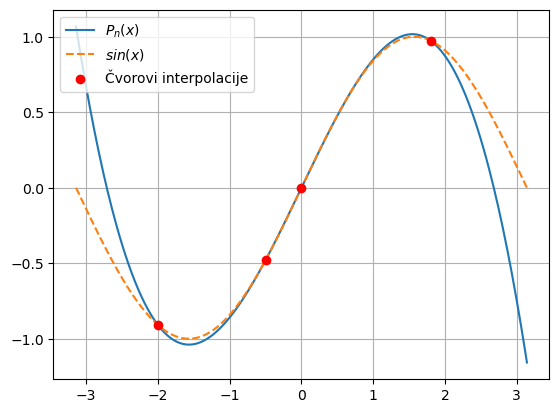

In [6]:
koef = Lagranz_koeficijenti(X, F)

xx = np.linspace(-np.pi, np.pi, 300)

plt.plot(xx, np.polyval(koef, xx), label='$P_n(x)$ ')
plt.plot(xx, np.sin(xx), '--', label='$sin(x)$')
plt.scatter(X, F, color='red', zorder=2, label='Čvorovi interpolacije')
plt.legend()
plt.grid(True)

Šta se dešava ako povećamo broj čvorova? Da li polinom nužno bolje aproksimira funkciju?

### Primer - **Rungeov fenomen**

 Kod ekvidistantnih čvorova na intervalu $[-1, 1]$, povećanje stepena polinoma ne mora da poboljšava aproksimaciju — naprotiv, greška na krajevima intervala može neograničeno rasti. Ovo je demonstrirano u narednoj ćeliji.


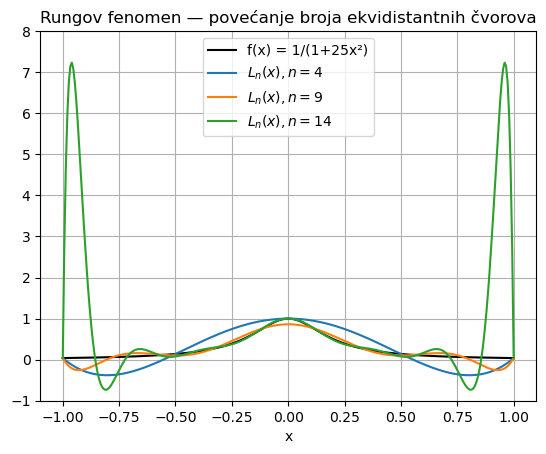

In [8]:
f_runge = lambda x: 1 / (1 + 25 * x**2)

xx = np.linspace(-1, 1,300)
plt.plot(xx, f_runge(xx), 'k-',label='f(x) = 1/(1+25x²)')

for n in [5, 10, 15]:
    X_n = np.linspace(-1, 1, n)
    F_n = f_runge(X_n)
    koef_n = Lagranz_koeficijenti(X_n, F_n)
    plt.plot(xx, np.polyval(koef_n, xx), label=f'$L_n(x), n={n-1}$')

plt.ylim(-1, 8)
plt.xlabel('x')
plt.title('Rungov fenomen — povećanje broja ekvidistantnih čvorova')
plt.legend()
plt.grid(True)
plt.show()

---
## 2. Njutnov interpolacioni polinom sa podeljenim razlikama

**Podeljene razlike** definišu se rekurzivno:
$$f[x_i] = f_i, \qquad f[x_i, \ldots, x_{i+k}] = \frac{f[x_{i+1},\ldots,x_{i+k}] - f[x_i,\ldots,x_{i+k-1}]}{x_{i+k} - x_i}.$$

**Njutnov oblik** interpolacionog polinoma je:
$$P(x) = f[x_0] + f[x_0,x_1](x-x_0) + f[x_0,x_1,x_2](x-x_0)(x-x_1) + \cdots + f[x_0,...,x_n](x-x_0)...(x-x_{n-1}).$$

**Prednost** ovog oblika: dodavanje novog čvora zahteva samo jedan novi sabirak — ne moramo ponovo računati sve od početka.


### Zadatak 3

Isprogramirati metodu `tablica_PR(X, F)` koja konstruiše tablicu podeljenih razlika. Prva kolona tablice sadrži podeljene razlike nultog reda (vrednosti funkcije u čvorovima). Potom isprogramirati metodu `NjutnPR_u_tacki(X, F, x)` koja izračunava vrednost Njutnovog interpolacionog polinoma (sa podeljenim razlikama) u tački `x`.

In [24]:
def tablica_PR(X, F):
    """
    Konstruiše tablicu podeljenih razlika.

    Ulaz:
        X : niz čvorova dužine n (ne moraju biti ekvidistantni)
        F : niz vrednosti funkcije u čvorovima

    Izlaz:
        Kvadratna matrica (n x n) podeljenih razlika.
    """
    n = len(X)
    tablica = np.zeros((n, n))
    tablica[:, 0] = F
    for i in range(1, n):
        brojioci = np.diff(tablica[:n - i + 1, i - 1])
        imenioci = X[i:] - X[:n - i]
        tablica[:n - i, i] = brojioci / imenioci
    return tablica

#drugi način
def tablica2(X,F):
    n = len(X)
    tablica = np.zeros((n, n))
    tablica[:, 0] = F
    for j in range(1, n):
        for i in range(n-j):
            tablica[i,j]=(tablica[i+1,j-1]-tablica[i,j-1])/(X[i+j]-X[i])
       
    return tablica


In [28]:
def NjutnPR_u_tacki(X, F, x):
    """
    Izračunava vrednost Njutnovog interpolacionog polinoma
    (sa podeljenim razlikama) u tački x.

    Ulaz:
        X : niz čvorova interpolacije
        F : niz vrednosti funkcije u čvorovima (F[i] = f(X[i]))
        x : tačka u kojoj se izračunava vrednost polinoma

    Izlaz:
        Vrednost interpolacionog polinoma P_n(x).

    """
    n = len(X)
    tablica = tablica_PR(X, F)
    S = 0
    w = 1
    for i in range(n):
        S = S + tablica[0, i] * w
        w = w * (x - X[i])
    return S

> **Za vežbu:** modifikovati prethodnu metodu tako da vraća sve vrednosti $P_k(x),\,k=0,1,...,n$.

###  Test primer

Dati su čvorovi $X = [0.5, 1, 2, 4]$ i vrednosti $F = 1/X$.  Koristeći prvih $n+1$ čvorova izračunati vrednosti interpolacionih polinoma stepena $n=1,2,3$, u tački $x = 0.8$ i uporediti sa tačnom vrednošću.


In [30]:
X = np.array([0.5, 1, 2, 4])
F = 1 / X
x = 0.8

T = tablica_PR(X, F)
print("\nTablica podeljenih razlika:")
print(np.round(T, 4))

y_tacno  = 1 / x
print(f"Tačna vrednost: 1/x = {y_tacno:.4f}\n")
for n in range (1,4):
  y_interp = NjutnPR_u_tacki(X[:n+1], F[:n+1], x)
  print(f"P_n(3), n={n}: {y_interp:.4f}")
  print(f"R_n(3), n={n}: {abs(y_interp - y_tacno):.2e}\n")



Tablica podeljenih razlika:
[[ 2.    -2.     1.    -0.25 ]
 [ 1.    -0.5    0.125  0.   ]
 [ 0.5   -0.125  0.     0.   ]
 [ 0.25   0.     0.     0.   ]]
Tačna vrednost: 1/x = 1.2500

P_n(3), n=1: 1.4000
R_n(3), n=1: 1.50e-01

P_n(3), n=2: 1.3400
R_n(3), n=2: 9.00e-02

P_n(3), n=3: 1.3220
R_n(3), n=3: 7.20e-02



In [ ]:
def NjutnPR_koeficijenti(X, F):
    """
    Računa koeficijente Njutnovog interpolacionog polinoma
    (sa podeljenim razlikama) u standardnom obliku za np.polyval.
    """
    tablica = tablica_PR(X, F)
    n = len(X)
    S = np.zeros(n)
    w = 1
    for i in range(n):
        S[n - i - 1:] = S[n - i - 1:] + tablica[0, i] * w
        w = np.convolve(w, [1, -X[i]])
    return S

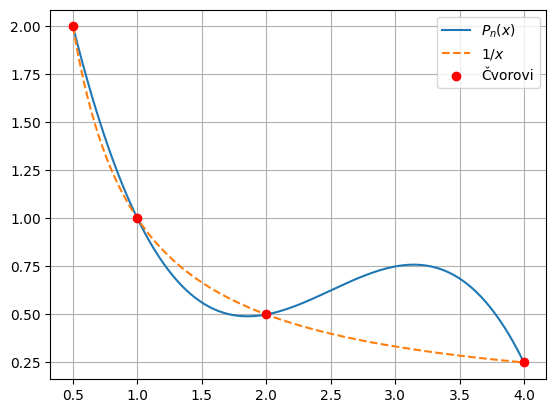

In [ ]:
koef = NjutnPR_koeficijenti(X, F)
xx = np.linspace(0.5, 4, 200)

plt.plot(xx, np.polyval(koef, xx), label='$P_n(x)$')
plt.plot(xx, 1 / xx, '--', label='$1/x$')
plt.scatter(X, F, color='red', zorder=5, label='Čvorovi')
plt.legend()
plt.grid(True)